# Small parity games: all positional profiles and winners

These examples use the max-parity convention: the player with the parity of the greatest priority occurring infinitely often wins. For each complete positional profile, the notebook follows the unique play from every start vertex, finds its eventual cycle, and reports the winner. Profile counts are small enough to inspect by hand.

In [ ]:
from pathlib import Path
import sys

# Jupyter may start in the repo root, the code folder, or notebooks/.
search_roots = (Path.cwd(), *Path.cwd().parents)
CODE = next(
    (candidate for root in search_roots
     for candidate in (root, root / 'code')
     if (candidate / 'src' / 'parity_bdd_lab').is_dir()),
    None,
)
if CODE is None:
    raise FileNotFoundError(
        f'Could not locate the code project from {Path.cwd()}. '
        'Open the repository or code folder in VS Code.'
    )
sys.path.insert(0, str(CODE / 'src'))

import pandas as pd
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
from parity_bdd_lab.examples import tiny_games
from parity_bdd_lab.game import enumerate_strategy_profiles, play, read_pg, strategy_profile_count

games = (*tiny_games(), read_pg(CODE / 'data' / 'games' / 'image_example.pg', vertex_labels=dict(enumerate('abcdefghi'))))
[(g.name, len(g.vertices), strategy_profile_count(g)) for g in games]

[('alternating_cycle_even', 2, 1),
 ('choice_and_self_loops', 3, 8),
 ('four_vertex_interaction', 4, 16),
 ('image_example', 9, 64)]

## Inspect every profile

Each row is one strategy profile and one starting vertex. `cycle` is the repeating part of the play; only priorities on this cycle determine the winner. The same profile can produce different outcomes from different starts.

In [9]:
def profile_label(profile):
    return f"P0 {dict(profile.player0)} | P1 {dict(profile.player1)}"

def profile_table(game):
    rows = []
    for profile_id, profile in enumerate(enumerate_strategy_profiles(game)):
        for start in game.vertices:
            result = play(game, profile, start)
            rows.append({
                'profile': profile_id,
                'choices': profile_label(profile),
                'start': start,
                'path prefix': result['prefix'],
                'cycle': result['cycle'],
                'cycle priorities': result['cycle_priorities'],
                'winner': f"Player {result['winner']}",
            })
    return pd.DataFrame(rows)

for game in games:
    print(f"{game.name}: {strategy_profile_count(game)} profiles")
    display(profile_table(game))

alternating_cycle_even: 1 profiles


,profile,choices,start,path prefix,cycle,cycle priorities,winner
0,0,P0 {0: 1} | P1 {1: 0},0,(),"(0, 1)","(0, 1)",Player 1
1,0,P0 {0: 1} | P1 {1: 0},1,(),"(1, 0)","(1, 0)",Player 1


choice_and_self_loops: 8 profiles


,profile,choices,start,path prefix,cycle,cycle priorities,winner
0,0,"P0 {0: 1} | P1 {1: 0, 2: 0}",0,(),"(0, 1)","(0, 2)",Player 0
1,0,"P0 {0: 1} | P1 {1: 0, 2: 0}",1,(),"(1, 0)","(2, 0)",Player 0
2,0,"P0 {0: 1} | P1 {1: 0, 2: 0}",2,"(2,)","(0, 1)","(0, 2)",Player 0
3,1,"P0 {0: 1} | P1 {1: 0, 2: 2}",0,(),"(0, 1)","(0, 2)",Player 0
4,1,"P0 {0: 1} | P1 {1: 0, 2: 2}",1,(),"(1, 0)","(2, 0)",Player 0
5,1,"P0 {0: 1} | P1 {1: 0, 2: 2}",2,(),"(2,)","(1,)",Player 1
6,2,"P0 {0: 1} | P1 {1: 1, 2: 0}",0,"(0,)","(1,)","(2,)",Player 0
7,2,"P0 {0: 1} | P1 {1: 1, 2: 0}",1,(),"(1,)","(2,)",Player 0
8,2,"P0 {0: 1} | P1 {1: 1, 2: 0}",2,"(2, 0)","(1,)","(2,)",Player 0
9,3,"P0 {0: 1} | P1 {1: 1, 2: 2}",0,"(0,)","(1,)","(2,)",Player 0


four_vertex_interaction: 16 profiles


,profile,choices,start,path prefix,cycle,cycle priorities,winner
0,0,"P0 {0: 1, 1: 0} | P1 {2: 1, 3: 0}",0,(),"(0, 1)","(1, 2)",Player 0
1,0,"P0 {0: 1, 1: 0} | P1 {2: 1, 3: 0}",1,(),"(1, 0)","(2, 1)",Player 0
2,0,"P0 {0: 1, 1: 0} | P1 {2: 1, 3: 0}",2,"(2,)","(1, 0)","(2, 1)",Player 0
3,0,"P0 {0: 1, 1: 0} | P1 {2: 1, 3: 0}",3,"(3,)","(0, 1)","(1, 2)",Player 0
4,1,"P0 {0: 1, 1: 0} | P1 {2: 1, 3: 3}",0,(),"(0, 1)","(1, 2)",Player 0
5,1,"P0 {0: 1, 1: 0} | P1 {2: 1, 3: 3}",1,(),"(1, 0)","(2, 1)",Player 0
6,1,"P0 {0: 1, 1: 0} | P1 {2: 1, 3: 3}",2,"(2,)","(1, 0)","(2, 1)",Player 0
7,1,"P0 {0: 1, 1: 0} | P1 {2: 1, 3: 3}",3,(),"(3,)","(3,)",Player 1
8,2,"P0 {0: 1, 1: 0} | P1 {2: 2, 3: 0}",0,(),"(0, 1)","(1, 2)",Player 0
9,2,"P0 {0: 1, 1: 0} | P1 {2: 2, 3: 0}",1,(),"(1, 0)","(2, 1)",Player 0


image_example: 64 profiles


,profile,choices,start,path prefix,cycle,cycle priorities,winner
0,0,"P0 {'a': 'b', 'c': 'b', 'e': 'i', 'f': 'g', 'g...",a,(),"(a, b)","(0, 2)",Player 0
1,0,"P0 {'a': 'b', 'c': 'b', 'e': 'i', 'f': 'g', 'g...",b,(),"(b, a)","(2, 0)",Player 0
2,0,"P0 {'a': 'b', 'c': 'b', 'e': 'i', 'f': 'g', 'g...",c,"(c,)","(b, a)","(2, 0)",Player 0
3,0,"P0 {'a': 'b', 'c': 'b', 'e': 'i', 'f': 'g', 'g...",d,"(d, e)","(i, h)","(3, 2)",Player 1
4,0,"P0 {'a': 'b', 'c': 'b', 'e': 'i', 'f': 'g', 'g...",e,"(e,)","(i, h)","(3, 2)",Player 1
5,0,"P0 {'a': 'b', 'c': 'b', 'e': 'i', 'f': 'g', 'g...",f,"(f, g)","(h, i)","(2, 3)",Player 1
6,0,"P0 {'a': 'b', 'c': 'b', 'e': 'i', 'f': 'g', 'g...",g,"(g,)","(h, i)","(2, 3)",Player 1
7,0,"P0 {'a': 'b', 'c': 'b', 'e': 'i', 'f': 'g', 'g...",h,(),"(h, i)","(2, 3)",Player 1
8,0,"P0 {'a': 'b', 'c': 'b', 'e': 'i', 'f': 'g', 'g...",i,(),"(i, h)","(3, 2)",Player 1
9,1,"P0 {'a': 'b', 'c': 'b', 'e': 'i', 'f': 'g', 'g...",a,(),"(a, b)","(0, 2)",Player 0


## Visualize the included `.pg` games

The graph helper colors and shapes vertices by owner and writes the priority inside each node. The first plot uses a fixed layout matching the supplied diagram; other games use a deterministic spring layout. For a standalone image file, use `python scripts/plot_pg.py data/games/image_example.pg` from the `code` directory.

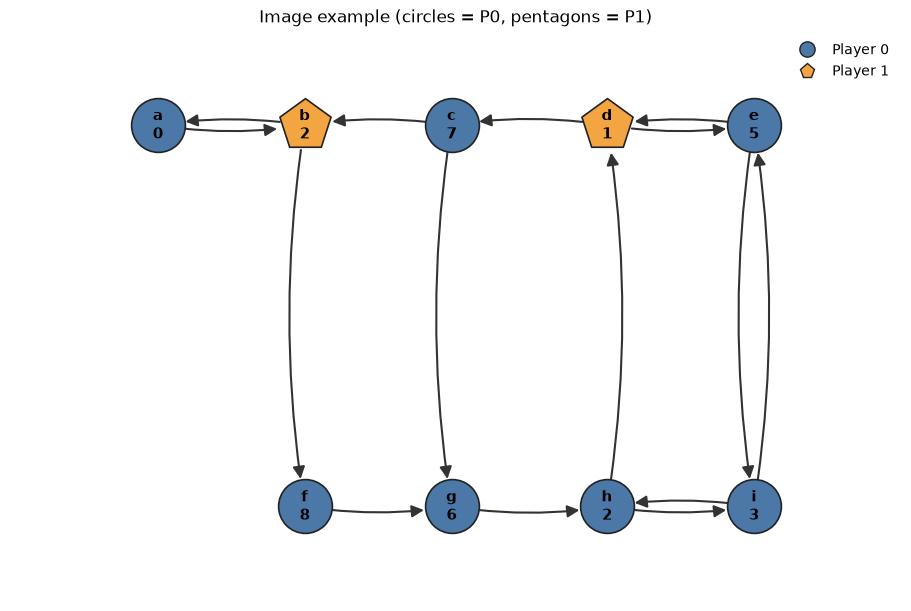

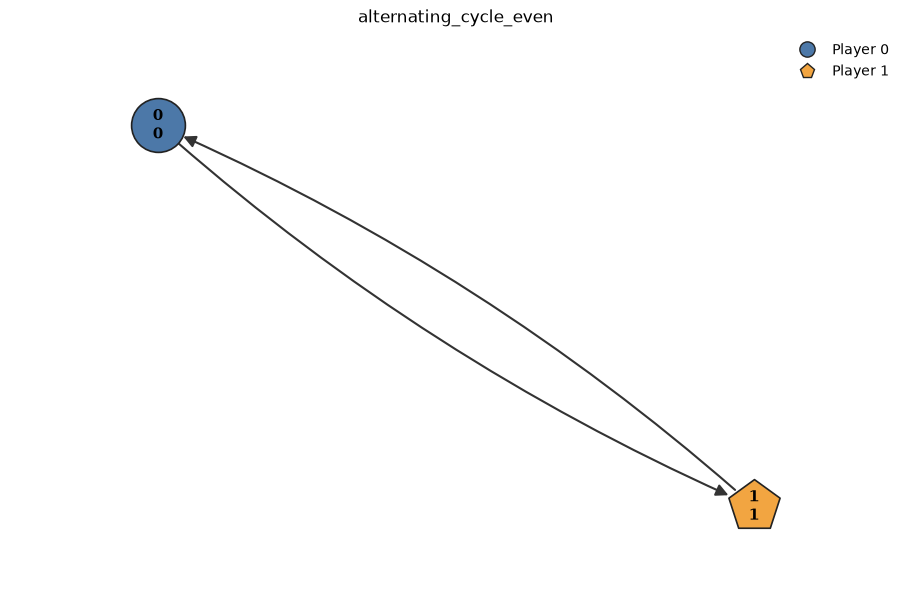

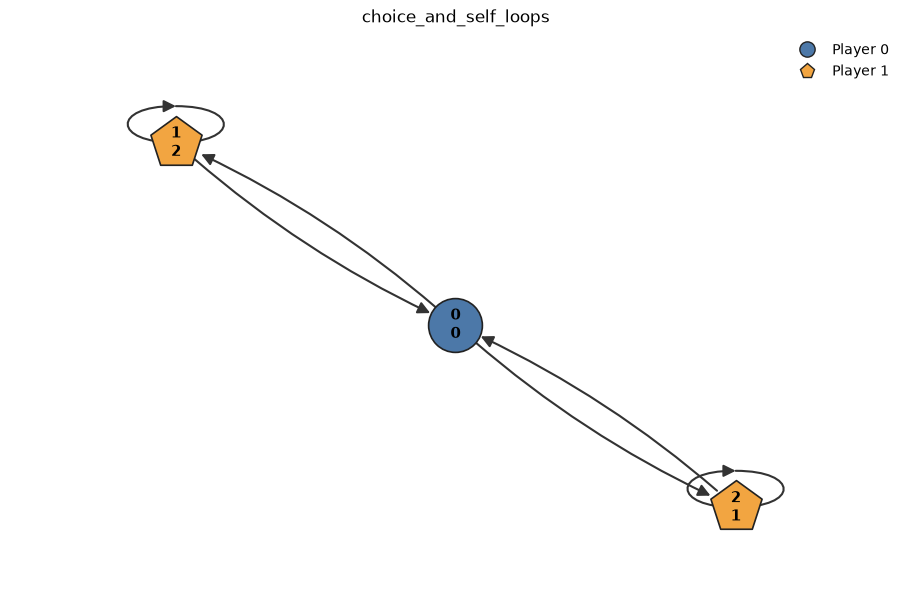

In [10]:
image_game = read_pg(CODE / 'data/games/image_example.pg', vertex_labels=dict(enumerate('abcdefghi')))
from parity_bdd_lab import draw_game, draw_pg

image_positions = {
    'a': (0.0, 1.5), 'b': (1.7, 1.5), 'c': (3.4, 1.5), 'd': (5.2, 1.5), 'e': (6.9, 1.5),
    'f': (1.7, 0.0), 'g': (3.4, 0.0), 'h': (5.2, 0.0), 'i': (6.9, 0.0),
}
draw_game(image_game, positions=image_positions, title='Image example (circles = P0, pentagons = P1)')

for pg_path in sorted((CODE / 'data/games').glob('*.pg')):
    if pg_path.stem != 'image_example':
        draw_pg(pg_path)

## All 64 profiles for the image game

This compact table lists each complete pair of positional strategies once and shows the winner and eventual cycle from every start vertex. The full per-start trace table above contains the corresponding prefixes and cycle priorities.

In [11]:
image_game = next(game for game in games if game.name == 'image_example')
rows = []
for profile_id, profile in enumerate(enumerate_strategy_profiles(image_game)):
    outcomes = {
        start: play(image_game, profile, start)
        for start in image_game.vertices
    }
    rows.append({
        'profile': profile_id,
        'Player 0 choices': dict(profile.player0),
        'Player 1 choices': dict(profile.player1),
        'winner by start (a–i)': {label: f"P{result['winner']}" for label, result in outcomes.items()},
        'cycle by start (a–i)': {label: result['cycle'] for label, result in outcomes.items()},
    })

image_profiles = pd.DataFrame(rows)
display(image_profiles)
assert len(image_profiles) == 64

,profile,Player 0 choices,Player 1 choices,winner by start (a–i),cycle by start (a–i)
0,0,"{'a': 'b', 'c': 'b', 'e': 'i', 'f': 'g', 'g': ...","{'b': 'a', 'd': 'e'}","{'a': 'P0', 'b': 'P0', 'c': 'P0', 'd': 'P1', '...","{'a': ('a', 'b'), 'b': ('b', 'a'), 'c': ('b', ..."
1,1,"{'a': 'b', 'c': 'b', 'e': 'i', 'f': 'g', 'g': ...","{'b': 'a', 'd': 'c'}","{'a': 'P0', 'b': 'P0', 'c': 'P0', 'd': 'P0', '...","{'a': ('a', 'b'), 'b': ('b', 'a'), 'c': ('b', ..."
2,2,"{'a': 'b', 'c': 'b', 'e': 'i', 'f': 'g', 'g': ...","{'b': 'f', 'd': 'e'}","{'a': 'P1', 'b': 'P1', 'c': 'P1', 'd': 'P1', '...","{'a': ('h', 'i'), 'b': ('h', 'i'), 'c': ('h', ..."
3,3,"{'a': 'b', 'c': 'b', 'e': 'i', 'f': 'g', 'g': ...","{'b': 'f', 'd': 'c'}","{'a': 'P1', 'b': 'P1', 'c': 'P1', 'd': 'P1', '...","{'a': ('h', 'i'), 'b': ('h', 'i'), 'c': ('h', ..."
4,4,"{'a': 'b', 'c': 'b', 'e': 'i', 'f': 'g', 'g': ...","{'b': 'a', 'd': 'e'}","{'a': 'P0', 'b': 'P0', 'c': 'P0', 'd': 'P1', '...","{'a': ('a', 'b'), 'b': ('b', 'a'), 'c': ('b', ..."
5,5,"{'a': 'b', 'c': 'b', 'e': 'i', 'f': 'g', 'g': ...","{'b': 'a', 'd': 'c'}","{'a': 'P0', 'b': 'P0', 'c': 'P0', 'd': 'P0', '...","{'a': ('a', 'b'), 'b': ('b', 'a'), 'c': ('b', ..."
6,6,"{'a': 'b', 'c': 'b', 'e': 'i', 'f': 'g', 'g': ...","{'b': 'f', 'd': 'e'}","{'a': 'P1', 'b': 'P1', 'c': 'P1', 'd': 'P1', '...","{'a': ('i', 'e'), 'b': ('i', 'e'), 'c': ('i', ..."
7,7,"{'a': 'b', 'c': 'b', 'e': 'i', 'f': 'g', 'g': ...","{'b': 'f', 'd': 'c'}","{'a': 'P1', 'b': 'P1', 'c': 'P1', 'd': 'P1', '...","{'a': ('i', 'e'), 'b': ('i', 'e'), 'c': ('i', ..."
8,8,"{'a': 'b', 'c': 'b', 'e': 'i', 'f': 'g', 'g': ...","{'b': 'a', 'd': 'e'}","{'a': 'P0', 'b': 'P0', 'c': 'P0', 'd': 'P1', '...","{'a': ('a', 'b'), 'b': ('b', 'a'), 'c': ('b', ..."
9,9,"{'a': 'b', 'c': 'b', 'e': 'i', 'f': 'g', 'g': ...","{'b': 'a', 'd': 'c'}","{'a': 'P0', 'b': 'P0', 'c': 'P0', 'd': 'P0', '...","{'a': ('a', 'b'), 'b': ('b', 'a'), 'c': ('b', ..."


## Unique cycles and their winners

A play may reach the same directed cycle at different offsets. This section groups cycles by rotation, so `(b, f, g, h, d, c)` and `(c, b, f, g, h, d)` appear once. Reversing edge direction is not treated as the same cycle. The winner is determined by the greatest priority on that cycle under the max-parity convention.

In [12]:
from collections import defaultdict

def canonical_cycle(cycle):
    cycle = tuple(cycle)
    rotations = [cycle[i:] + cycle[:i] for i in range(len(cycle))]
    return min(rotations, key=lambda rotation: tuple(map(str, rotation)))

cycle_occurrences = defaultdict(list)
for profile_id, profile in enumerate(enumerate_strategy_profiles(image_game)):
    for start in image_game.vertices:
        result = play(image_game, profile, start)
        cycle = canonical_cycle(result['cycle'])
        cycle_occurrences[cycle].append({
            'profile': profile_id,
            'start': start,
        })

unique_cycle_rows = []
for cycle, occurrences in sorted(cycle_occurrences.items(), key=lambda item: tuple(map(str, item[0]))):
    priorities = tuple(image_game.priority[v] for v in cycle)
    max_priority = max(priorities)
    unique_cycle_rows.append({
        'cycle': cycle,
        'cycle priorities': priorities,
        'greatest recurring priority': max_priority,
        'winner': f"Player {max_priority % 2}",
        'number of profile/start occurrences': len(occurrences),
        'starts where observed': tuple(sorted({entry['start'] for entry in occurrences})),
    })

unique_cycles = pd.DataFrame(unique_cycle_rows)
display(unique_cycles)

,cycle,cycle priorities,greatest recurring priority,winner,number of profile/start occurrences,starts where observed
0,"(a, b)","(0, 2)",2,Player 0,112,"(a, b, c, d, e, f, g, h, i)"
1,"(b, f, g, h, d, c)","(2, 8, 6, 2, 1, 7)",8,Player 0,34,"(a, b, c, d, e, f, g, h, i)"
2,"(b, f, g, h, i, e, d, c)","(2, 8, 6, 2, 3, 5, 1, 7)",8,Player 0,9,"(a, b, c, d, e, f, g, h, i)"
3,"(c, g, h, d)","(7, 6, 2, 1)",7,Player 1,60,"(a, b, c, d, e, f, g, h, i)"
4,"(c, g, h, i, e, d)","(7, 6, 2, 3, 5, 1)",7,Player 1,16,"(a, b, c, d, e, f, g, h, i)"
5,"(d, e)","(1, 5)",5,Player 1,101,"(a, b, c, d, e, f, g, h, i)"
6,"(d, e, i, h)","(1, 5, 3, 2)",5,Player 1,31,"(a, b, c, d, e, f, g, h, i)"
7,"(e, i)","(5, 3)",5,Player 1,100,"(a, b, c, d, e, f, g, h, i)"
8,"(h, i)","(2, 3)",3,Player 1,113,"(a, b, c, d, e, f, g, h, i)"


## Cycles arising under a strategy that forces the win

A cycle appearing in one strategy profile does not by itself show that its winner can force that outcome. For each player strategy and starting vertex, the next cell checks every positional strategy of the opponent. It keeps a cycle only when the player wins against all those replies from that start. A winning strategy can allow more than one eventual cycle; the listed cycles are outcomes compatible with a guaranteed win, not necessarily one exact cycle the winner can force against every reply. Parity games admit positional winning strategies, so this exhaustive check is appropriate for these finite examples.

In [13]:
all_profiles = tuple(enumerate_strategy_profiles(image_game))
forced_cycle_data = {}

for player in (0, 1):
    # Keep one copy of each positional strategy for this player.
    own_strategies = {
        tuple(profile.for_player(player).items()): dict(profile.for_player(player))
        for profile in all_profiles
    }
    for own_strategy in own_strategies.values():
        opponent_replies = [
            profile for profile in all_profiles
            if profile.for_player(player) == own_strategy
        ]
        for start in image_game.vertices:
            outcomes = [play(image_game, profile, start) for profile in opponent_replies]
            if all(outcome['winner'] == player for outcome in outcomes):
                for outcome in outcomes:
                    cycle = canonical_cycle(outcome['cycle'])
                    key = (player, cycle)
                    item = forced_cycle_data.setdefault(key, {
                        'starts': set(),
                        'witness strategies': set(),
                    })
                    item['starts'].add(start)
                    item['witness strategies'].add(tuple(own_strategy.items()))

forced_cycle_rows = []
for (player, cycle), item in sorted(
    forced_cycle_data.items(), key=lambda pair: (pair[0][0], tuple(map(str, pair[0][1])))
):
    priorities = tuple(image_game.priority[v] for v in cycle)
    forced_cycle_rows.append({
        'cycle': cycle,
        'cycle priorities': priorities,
        'winner who can force a win': f'Player {player}',
        'winning from starts': tuple(sorted(item['starts'])),
        'number of witness strategies': len(item['witness strategies']),
        'example winning strategy': dict(next(iter(item['witness strategies']))),
    })

forced_winning_cycles = pd.DataFrame(forced_cycle_rows)
display(forced_winning_cycles)

,cycle,cycle priorities,winner who can force a win,winning from starts,number of witness strategies,example winning strategy
0,"(d, e)","(1, 5)",Player 1,"(a, b, c, d, e, f, g, h, i)",2,"{'b': 'a', 'd': 'e'}"
1,"(d, e, i, h)","(1, 5, 3, 2)",Player 1,"(a, b, c, d, e, f, g, h, i)",2,"{'b': 'a', 'd': 'e'}"
2,"(e, i)","(5, 3)",Player 1,"(a, b, c, d, e, f, g, h, i)",2,"{'b': 'a', 'd': 'e'}"
3,"(h, i)","(2, 3)",Player 1,"(a, b, c, d, e, f, g, h, i)",2,"{'b': 'a', 'd': 'e'}"


## Forced multistrategies as priority-carrying chains

`Chain-MS` builds a forced-winning multistrategy for each player using its own chain-quotient solver and cycle-based justification graph. Each displayed chain keeps its full vertex sequence and the maximum priority on that chain; `*_chain_nodes` reports the distinct vertices represented by the chains. The result also stores a BDD relation between chain IDs; each ID maps back to its vertex tuple.


In [ ]:
from parity_bdd_lab import chain_multistrategy

multistrategy = chain_multistrategy(image_game)
possible_chain_rows = [
    {'chain id': i, 'chain': chain.vertices, 'chain priority': chain.priority}
    for i, chain in enumerate(multistrategy.possible_chain_ids)
]
display(pd.DataFrame(possible_chain_rows))
print('Possible-cycle relation BDD nodes:', len(multistrategy.possible_cycle_bdd))

chain_rows = [
    {'player': player, 'chain': chain.vertices, 'chain priority': chain.priority}
    for player, chains in ((0, multistrategy.even_chains), (1, multistrategy.odd_chains))
    for chain in chains
]
display(pd.DataFrame(chain_rows))
print('Even chain-covered nodes:', multistrategy.even_chain_nodes)
print('Odd chain-covered nodes:', multistrategy.odd_chain_nodes)
print('Total possible and forced chain-relation BDD nodes:', multistrategy.bdd_nodes)


## A simple `dd` BDD and MDD check

`dd.autoref.BDD` represents Boolean variables; `dd.mdd.MDD` represents integer-valued variables with finite domains. Here we create each manager to confirm the package interfaces are ready for further symbolic encodings.

In [14]:
from parity_bdd_lab import new_bdd, new_mdd

bdd = new_bdd(['x', 'y'])
formula = bdd.add_expr('x & ~y')
print('BDD formula:', bdd.to_expr(formula))

mdd = new_mdd({'vertex': 4, 'owner': 2})
print('MDD variables:', mdd.vars)
print('BDD manager nodes:', len(bdd))

BDD formula: (~ ite(x, y, TRUE))
MDD variables: {'vertex': {'level': 0, 'len': 4}, 'owner': {'level': 1, 'len': 2}}
BDD manager nodes: 4


## Scaling note

The number of complete positional profiles is the product of the out-degrees of every vertex. To estimate cost before enumerating, use `strategy_profile_count(game)`. Enumeration is guarded at 10,000 profiles by default; set `max_profiles=None` or a larger explicit limit only when the resulting table is manageable.